In [1]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(14)
n = 100

monthly_income = rng.integers(30000, 120001, n)
monthly_expenses = rng.integers(15000, 45001, n)

df = pd.DataFrame({
    "application_id": [
        f"SIM{i:03d}" for i in range(1, n + 1)
    ],
    "monthly_income": monthly_income,
    "monthly_expenses": monthly_expenses,
    "loan_amount": rng.integers(
        1, 21, n
    ) * 50000,
    "loan_term": rng.choice(
        [12, 24, 36, 48, 60], n
    ),
    "work_experience": rng.integers(0, 16, n),
    "document_complete": rng.choice(
        ["Yes", "No"],
        n,
        p=[0.8, 0.2]
    )
})

df.to_csv(
    "simulated_loan_data.csv",
    index=False,
    encoding="utf-8-sig"
)

print("資料筆數：", len(df))
display(df.head())


資料筆數： 100


,application_id,monthly_income,monthly_expenses,loan_amount,loan_term,work_experience,document_complete
0,SIM001,43524,33063,450000,60,3,Yes
1,SIM002,104789,40349,100000,48,6,Yes
2,SIM003,88801,17742,500000,60,15,No
3,SIM004,62485,27899,200000,60,9,Yes
4,SIM005,37980,36537,900000,36,1,Yes


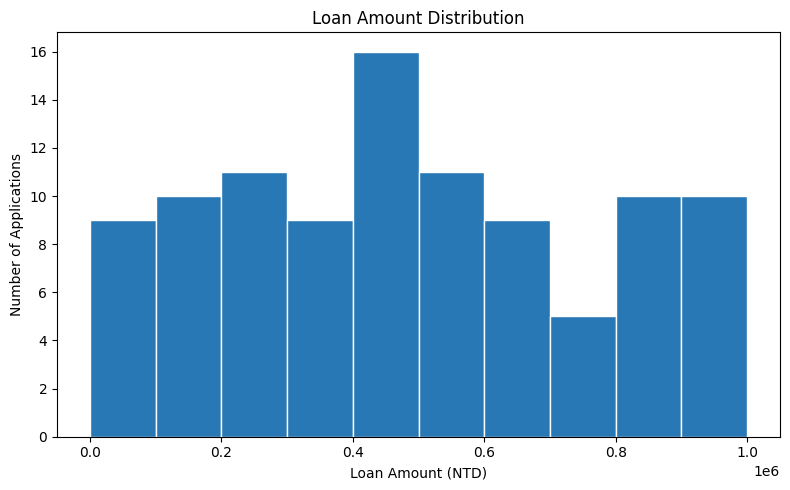

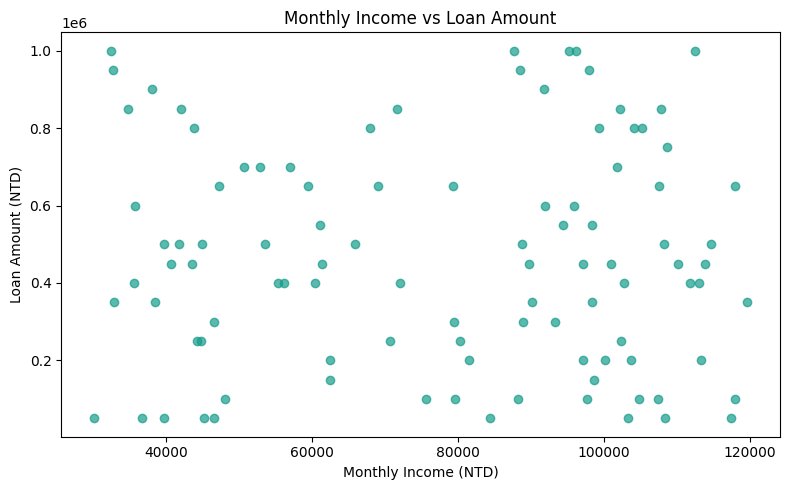

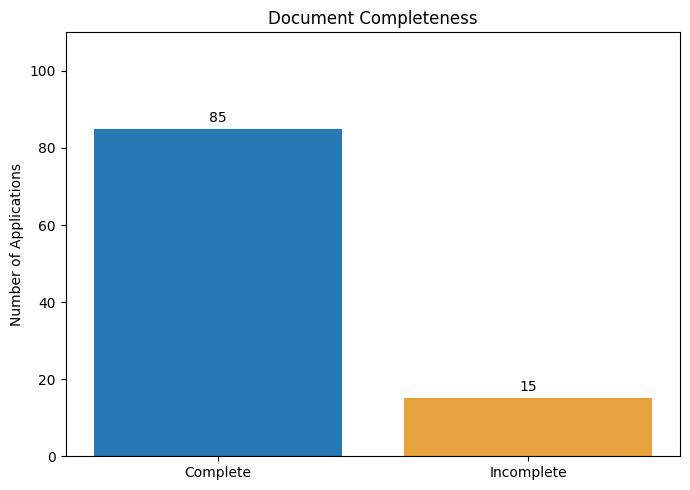

=== EDA SUMMARY ===
資料筆數： 100
平均申貸金額： 465500
申貸金額中位數： 450000
收入與申貸金額相關係數： -0.02
文件完整件數： 85
文件不完整件數： 15
文件不完整比例： 15.0 %


In [2]:

import matplotlib.pyplot as plt
import numpy as np

# 圖 1：申貸金額分布
plt.figure(figsize=(8, 5))
plt.hist(
    df["loan_amount"],
    bins=np.arange(0, 1100000, 100000),
    color="#2878B5",
    edgecolor="white"
)
plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount (NTD)")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.savefig("01_loan_amount_distribution.png", dpi=200)
plt.show()

# 圖 2：月收入與申貸金額關係
plt.figure(figsize=(8, 5))
plt.scatter(
    df["monthly_income"],
    df["loan_amount"],
    alpha=0.7,
    color="#169C8A"
)
plt.title("Monthly Income vs Loan Amount")
plt.xlabel("Monthly Income (NTD)")
plt.ylabel("Loan Amount (NTD)")
plt.tight_layout()
plt.savefig("02_income_vs_loan.png", dpi=200)
plt.show()

# 圖 3：文件完整性
counts = df["document_complete"].value_counts()
counts = counts.reindex(["Yes", "No"], fill_value=0)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Complete", "Incomplete"],
    counts.values,
    color=["#2878B5", "#E6A23C"]
)
plt.bar_label(bars, padding=3)
plt.title("Document Completeness")
plt.ylabel("Number of Applications")
plt.ylim(0, 110)
plt.tight_layout()
plt.savefig("03_document_completeness.png", dpi=200)
plt.show()

# 輸出統計結果
print("=== EDA SUMMARY ===")
print("資料筆數：", len(df))
print("平均申貸金額：", round(df["loan_amount"].mean()))
print("申貸金額中位數：", round(df["loan_amount"].median()))
print(
    "收入與申貸金額相關係數：",
    round(df["monthly_income"].corr(df["loan_amount"]), 3)
)
print("文件完整件數：", counts["Yes"])
print("文件不完整件數：", counts["No"])
print(
    "文件不完整比例：",
    round(counts["No"] / len(df) * 100, 1),
    "%"
)


In [3]:

import pandas as pd

# 1. 檢查缺失值
print("=== 缺失值檢查 ===")
print(df.isnull().sum())

# 2. 檢查重複案件
print("\n=== 重複案件檢查 ===")
print("重複申請編號：",
      df["application_id"].duplicated().sum())

# 3. 檢查數值範圍
print("\n=== 數值欄位統計 ===")
print(df.describe())

# 4. 檢查不合理數值
invalid = (
    (df["monthly_income"] <= 0) |
    (df["monthly_expenses"] < 0) |
    (df["loan_amount"] <= 0) |
    (df["loan_term"] <= 0) |
    (df["work_experience"] < 0)
)

print("\n不合理數值案件數：", invalid.sum())

# 5. 檢查文件完整性
print("\n=== 文件完整性 ===")
print(df["document_complete"].value_counts())

# 6. 輸出品質檢查結果
summary = pd.DataFrame({
    "check": [
        "total_records",
        "missing_values",
        "duplicate_ids",
        "invalid_numeric_records",
        "incomplete_documents"
    ],
    "count": [
        len(df),
        int(df.isnull().sum().sum()),
        int(df["application_id"].duplicated().sum()),
        int(invalid.sum()),
        int((df["document_complete"] == "No").sum())
    ]
})

summary.to_csv(
    "data_quality_report.csv",
    index=False,
    encoding="utf-8-sig"
)

display(summary)


=== 缺失值檢查 ===
application_id       0
monthly_income       0
monthly_expenses     0
loan_amount          0
loan_term            0
work_experience      0
document_complete    0
dtype: int64

=== 重複案件檢查 ===
重複申請編號： 0

=== 數值欄位統計 ===
       monthly_income  monthly_expenses     loan_amount   loan_term  \
count      100.000000        100.000000      100.000000  100.000000   
mean     77830.710000      29221.050000   465500.000000   34.080000   
std      27554.398916       9131.247793   285835.210701   18.347752   
min      30046.000000      15146.000000    50000.000000   12.000000   
25%      49958.500000      21355.750000   237500.000000   12.000000   
50%      86039.000000      27903.000000   450000.000000   36.000000   
75%     101889.000000      38174.750000   662500.000000   48.000000   
max     119638.000000      44940.000000  1000000.000000   60.000000   

       work_experience  
count       100.000000  
mean          8.220000  
std           4.520615  
min           0.000000  
25%  

,check,count
0,total_records,100
1,missing_values,0
2,duplicate_ids,0
3,invalid_numeric_records,0
4,incomplete_documents,15
